# Decide what to inspect — classification and probability

## Goal
Build a prediction from a decision contract, not from an algorithm name. This is an executed tutorial using original synthetic data. **Do not infer real operational usefulness from these results.**

Prediction cutoff: before inspection. Target: failure within 48 hours. Unit: machine snapshot. Training labels must have matured. All snapshots of a machine stay together. Miss cost 10, false alarm 1; capacity is explicit.

## Setup
Extract the entire learning kit before opening this notebook. Install `requirements.txt` in a Python 3.12 virtual environment. No network or credentials are used during execution. Freeze and evaluate only after development choices are settled. The test-set guard is a learning convention, not secure access control.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from workshop import *
plt.rcParams.update({'figure.figsize': (8.5, 4.2), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18})
COLORS = {'actual': '#263a36', 'model': '#4c713d', 'baseline': '#82739b'}
SEED = 42
PROJECT = 'maintenance'
rows = make_dataset(PROJECT, SEED)
classification = PROJECT == 'maintenance'
UNITS = 'kWh/day' if PROJECT == 'energy' else 'packs/store-week' if PROJECT == 'demand' else 'probability'
train, validation, test = (partition(rows, part) for part in ('train','validation','test'))
print({part: len(partition(rows, part)) for part in ('train','validation','test')})

{'train': 112, 'validation': 40, 'test': 40}


## Steps
### 1. Inspect the grain and information cutoff
A row has an entity, an ordered time, available inputs, an outcome, and an assigned split. Inspect only training outcomes here. Original schema, timing, and licenses are documented in DATA.md.

In [2]:
print(json.dumps(train[:3], indent=2))
assert len({r['id'] for r in rows}) == len(rows)
assert all(np.isfinite(r['x']).all() and np.isfinite(r['y']) for r in rows)

[
  {
    "id": "m0-v0",
    "entity": "machine-0",
    "time": 0,
    "x": [
      -0.49735921155661345,
      -1.8973443806171417
    ],
    "y": 0,
    "baseline": 0.17857142857142858,
    "segment": "line B",
    "split": "train"
  },
  {
    "id": "m0-v1",
    "entity": "machine-0",
    "time": 1,
    "x": [
      -1.5261599849909544,
      1.4952548230066895
    ],
    "y": 0,
    "baseline": 0.17857142857142858,
    "segment": "line B",
    "split": "train"
  },
  {
    "id": "m0-v2",
    "entity": "machine-0",
    "time": 2,
    "x": [
      1.4128108946606517,
      -0.0012930873781442642
    ],
    "y": 0,
    "baseline": 0.17857142857142858,
    "segment": "line B",
    "split": "train"
  }
]


### 2. Write a falsifiable hypothesis
**Pause:** write why these inputs should improve on the baseline. Name a plausible failure mechanism. An observation such as lower training loss will not prove this hypothesis.

Professional lenses: domain experts inspect the target/proxies; statisticians inspect the split; engineers inspect availability and reproducibility; owners inspect cost; reviewers look for optimistic evidence.

In [3]:
HYPOTHESIS = 'Available measurements and known plans may improve on a simple baseline.'
INTERPRETATION = ''  # Replace after viewing your frozen evaluation.
NEXT_ACTION = ''     # Owner, monitoring cadence, manual fallback, rollback trigger.
print(HYPOTHESIS)

Available measurements and known plans may improve on a simple baseline.


### 3. Establish a baseline before fitting
The baseline is the training mean (energy), training prevalence (maintenance), or the same store 12 synthetic weeks earlier (demand). The synthetic demand cycle has period 12; this is not a universal retail season.

In [4]:
x_train, y_train = arrays(train)
x_val, y_val = arrays(validation)
baseline_validation = metrics(y_val, np.array([r['baseline'] for r in validation]), classification)
print(json.dumps(baseline_validation, indent=2))

{
  "log_loss": 0.34931592459555916,
  "brier": 0.09617346938775509,
  "precision": null,
  "recall": 0.0,
  "specificity": 1.0,
  "average_precision": 0.1,
  "auc": 0.5,
  "cost": 40,
  "alerts": 0,
  "tp": 0,
  "fp": 0,
  "fn": 4,
  "tn": 36
}


### 4. One hand update, then a transparent algorithm
For standardized regression with x=2, target=1, intercept=0, weight=0: prediction=0, the weight gradient of half squared loss is −2. At learning rate 0.1, weight becomes 0.2. The full implementation adds an unpenalized intercept and optional ridge penalty. Logistic regression substitutes sigmoid probabilities and log loss.

{'gradient': -2.0, 'new_weight': 0.2}
{
  "log_loss": 0.2957749081208184,
  "brier": 0.08403121265323205,
  "precision": 0.0,
  "recall": 0.0,
  "specificity": 0.9166666666666666,
  "average_precision": 0.36408730158730157,
  "auc": 0.888888888888889,
  "cost": 43,
  "alerts": 3,
  "tp": 0,
  "fp": 3,
  "fn": 4,
  "tn": 33
}


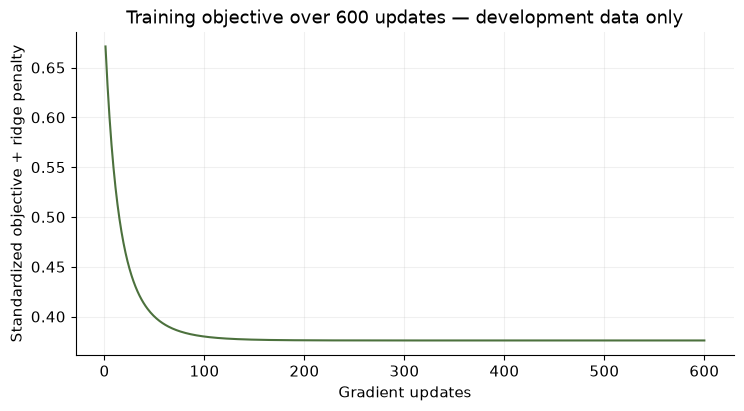

In [5]:
x, target, weight, rate = 2., 1., 0., .1
gradient_one = x * (weight * x - target)
print({'gradient': gradient_one, 'new_weight': weight - rate * gradient_one})
manual = manual_fit(train, classification, penalty=.1)
manual_validation = manual_predict(manual, validation)
print(json.dumps(metrics(y_val, manual_validation, classification), indent=2))
plt.plot(np.arange(1, len(manual['losses']) + 1), manual['losses'], color=COLORS['model'])
plt.title('Training objective over 600 updates — development data only')
plt.xlabel('Gradient updates'); plt.ylabel('Standardized objective + ridge penalty'); plt.show()

The curve is the optimized training objective, not a claim about test performance. Training statistics are fitted on the training partition only. A fixed seed reproduces a sample, not a guarantee of generalization.

### 5. Use a fitted preprocessing-plus-model pipeline
Keep the scaler and predictor together. `fit` sees training only; validation is transform/predict only. The ridge strength below is scaled to match the browser objective. Read `workshop.py` to connect the short library call to the transparent implementation.

In [6]:
pipeline = pipeline_for(classification, penalty=.1, n_train=len(train))
pipeline.fit(x_train, y_train)
validation_prediction = output(pipeline, x_val, classification)
print(json.dumps(metrics(y_val, validation_prediction, classification), indent=2))

{
  "log_loss": 0.2957650758631301,
  "brier": 0.08402942047602954,
  "precision": 0.0,
  "recall": 0.0,
  "specificity": 0.9166666666666666,
  "average_precision": 0.36408730158730157,
  "auc": 0.888888888888889,
  "cost": 43,
  "alerts": 3,
  "tp": 0,
  "fp": 3,
  "fn": 4,
  "tn": 33
}


### 6. Try the plausible mistake: give the model its future outcome
This deliberate diagnostic adds y as an input on both training and validation rows. It cannot be supplied at prediction time. A dramatic apparent improvement is evidence of a broken protocol, not a superior deployable model.

In [7]:
leaked = manual_fit(train, classification, leak=True, penalty=0)
leaked_prediction = manual_predict(leaked, validation)
print('Honest validation:', metrics(y_val, manual_validation, classification))
print('Leaked validation:', metrics(y_val, leaked_prediction, classification))
# Deliberately discard the leaked model before any final evaluation.
del leaked, leaked_prediction

Honest validation: {'log_loss': 0.2957749081208184, 'brier': 0.08403121265323205, 'precision': 0.0, 'recall': 0.0, 'specificity': 0.9166666666666666, 'average_precision': 0.36408730158730157, 'auc': 0.888888888888889, 'cost': 43, 'alerts': 3, 'tp': 0, 'fp': 3, 'fn': 4, 'tn': 33}
Leaked validation: {'log_loss': 0.012307168031085742, 'brier': 0.00016737487540419558, 'precision': 1.0, 'recall': 1.0, 'specificity': 1.0, 'average_precision': 1.0, 'auc': 1.0, 'cost': 0, 'alerts': 4, 'tp': 4, 'fp': 0, 'fn': 0, 'tn': 36}


### 7. Compare a bounded development search
Five fixed candidates share the same train/validation observations. Trees, forests, and boosting can represent nonlinear patterns; complexity is useful only if honest evidence supports it. A ranking on this small synthetic validation sample has no automatic statistical significance.

In [8]:
comparisons = development_comparison(rows, classification)
for result in comparisons:
    print(result['model'], round(result['log_loss'] if classification else result['mae'], 4))

linear_or_logistic 0.2605
ridge_0.1 0.2958
one_split_tree 0.2727
random_forest 0.3889
gradient_boosting 0.2705


**Decision record:** record which result surprised you, what assumption it challenges, and the next discriminating experiment. Do not choose a model by looking at final-test labels. The remaining cells use the predeclared ridge/logistic pipeline for teaching consistency; they do not pretend it won every search.

### 8. Separate probabilities from operating decisions
Threshold changes affect alerts, precision, recall, and cost; they do not change the underlying predicted probabilities. Here one missed failure costs 10 illustrative units and a false alarm costs 1.

0.1 {'log_loss': 0.2957650758631301, 'brier': 0.08402942047602954, 'precision': 0.13333333333333333, 'recall': 1.0, 'specificity': 0.2777777777777778, 'average_precision': 0.36408730158730157, 'auc': 0.888888888888889, 'cost': 26, 'alerts': 30, 'tp': 4, 'fp': 26, 'fn': 0, 'tn': 10}
0.3 {'log_loss': 0.2957650758631301, 'brier': 0.08402942047602954, 'precision': 0.0, 'recall': 0.0, 'specificity': 0.9166666666666666, 'average_precision': 0.36408730158730157, 'auc': 0.888888888888889, 'cost': 43, 'alerts': 3, 'tp': 0, 'fp': 3, 'fn': 4, 'tn': 33}
0.5 {'log_loss': 0.2957650758631301, 'brier': 0.08402942047602954, 'precision': None, 'recall': 0.0, 'specificity': 1.0, 'average_precision': 0.36408730158730157, 'auc': 0.888888888888889, 'cost': 40, 'alerts': 0, 'tp': 0, 'fp': 0, 'fn': 4, 'tn': 36}
0.7 {'log_loss': 0.2957650758631301, 'brier': 0.08402942047602954, 'precision': None, 'recall': 0.0, 'specificity': 1.0, 'average_precision': 0.36408730158730157, 'auc': 0.888888888888889, 'cost': 40, 

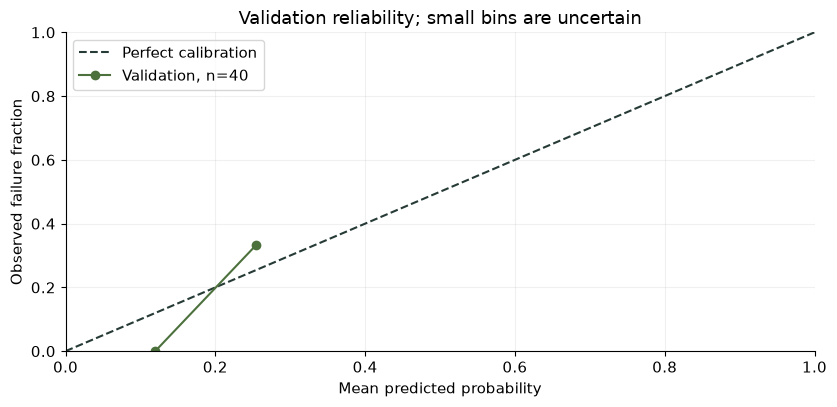

In [9]:
for threshold in (.1,.3,.5,.7):
    print(threshold,metrics(y_val,validation_prediction,True,threshold))
from sklearn.calibration import calibration_curve
observed,predicted=calibration_curve(y_val,validation_prediction,n_bins=5,strategy='uniform')
fig,ax=plt.subplots()
ax.plot([0,1],[0,1],'--',color=COLORS['actual'],label='Perfect calibration')
ax.plot(predicted,observed,'o-',color=COLORS['model'],label=f'Validation, n={len(y_val)}')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed failure fraction',title='Validation reliability; small bins are uncertain');ax.legend();plt.tight_layout();plt.show()

### 9. Fit calibration and choose a policy without the final test
The original predictor stays frozen. The first five validation machines calibrate its probabilities; the other five choose a threshold. Inspection capacity is at most six alerts per 20-row policy sample (equivalent rate to 12 per 40). The partitions are tiny and only illustrate the protocol, not adequate safety evidence. Calibration can worsen results on small samples.

In [10]:
calibrated,threshold,policy_result=calibrate_and_select_policy(pipeline,validation)
print('Chosen threshold:',threshold)
print('Policy development evidence:',policy_result)
assert policy_result['alerts']<=6

Chosen threshold:

 0.2
Policy development evidence: {'log_loss': 0.3067107989860628, 'brier': 0.08727949737889643, 'precision': 0.3333333333333333, 'recall': 1.0, 'specificity': 0.7777777777777778, 'average_precision': 0.3333333333333333, 'auc': 0.8333333333333334, 'cost': 4, 'alerts': 6, 'tp': 2, 'fp': 4, 'fn': 0, 'tn': 14}


### Freeze probabilities and threshold; open the unseen-machine test
No machine in this test occurs in training or calibration/policy selection. This does not by itself establish future temporal validity: real training labels must have matured before the inspection shift.

In [11]:
frozen=freeze(calibrated,True,threshold)
final_result=frozen.evaluate_once(test)
x_test,y_test=arrays(test)
final_probability=output(frozen.model,x_test,True)
print('Final frozen evidence:',final_result)
print('Prevalence baseline, same policy:',metrics(y_test,np.array([r['baseline'] for r in test]),True,threshold))
for segment in sorted({r['segment'] for r in test}):
    sample=[r for r in test if r['segment']==segment]
    x_slice,y_slice=arrays(sample)
    print(segment,'n=',len(sample),metrics(y_slice,output(frozen.model,x_slice,True),True,threshold))

Final frozen evidence: {'log_loss': 0.2946254313993991, 'brier': 0.08372128474718407, 'precision': 0.3076923076923077, 'recall': 0.8, 'specificity': 0.7428571428571429, 'average_precision': 0.7, 'auc': 0.8457142857142858, 'cost': 19, 'alerts': 13, 'tp': 4, 'fp': 9, 'fn': 1, 'tn': 26}
Prevalence baseline, same policy: {'log_loss': 0.3874673321829354, 'brier': 0.11224489795918366, 'precision': None, 'recall': 0.0, 'specificity': 1.0, 'average_precision': 0.125, 'auc': 0.5, 'cost': 50, 'alerts': 0, 'tp': 0, 'fp': 0, 'fn': 5, 'tn': 35}
line A n= 20 {'log_loss': 0.4118323390136197, 'brier': 0.12728439549893714, 'precision': 0.42857142857142855, 'recall': 0.75, 'specificity': 0.75, 'average_precision': 0.7166666666666667, 'auc': 0.796875, 'cost': 14, 'alerts': 7, 'tp': 3, 'fp': 4, 'fn': 1, 'tn': 12}
line B n= 20 {'log_loss': 0.17741852378517858, 'brier': 0.04015817399543101, 'precision': 0.16666666666666666, 'recall': 1.0, 'specificity': 0.7368421052631579, 'average_precision': 1.0, 'auc': 1

An AUC or average-precision score is not a deployment decision. Check cost, capacity, calibration evidence, failure consequences, subgroup counts, and human oversight. These synthetic line A/B slices are operational categories, not a comprehensive fairness audit.

## Checks
Run the companion unit tests after rebuilding the model. Then try the following development-only experiments; use a fresh protocol if you change the model after seeing a final test.

In [12]:
import unittest
from test_workshop import WorkshopChecks
suite=unittest.defaultTestLoader.loadTestsFromTestCase(WorkshopChecks)
result=unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful()

.

.

.

.

.

...

.

.

.

.

----------------------------------------------------------------------
Ran 10 tests in 0.096s

OK


### Learning curves, regularization, and seed stability
Repeat prefixes of the training period (or whole training machines), not random partial snapshots of a group. Measure training and validation separately. More data or a smaller training loss can fail to help if representation, labels, or deployment assumptions are wrong.

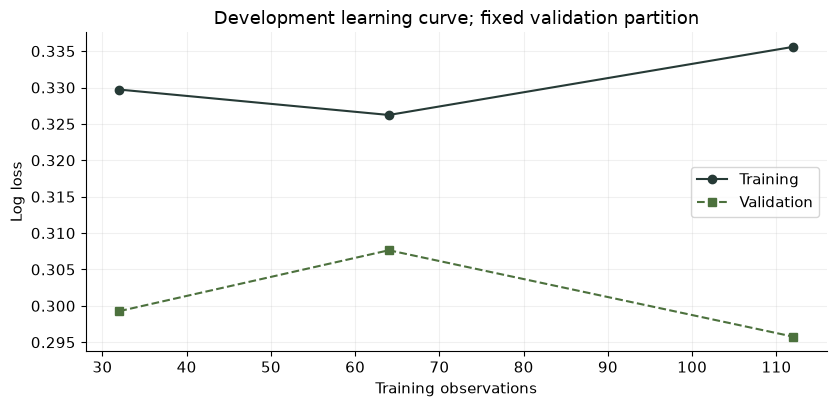

seed 42 {'log_loss': 0.2957650758631301, 'brier': 0.08402942047602954, 'precision': 0.0, 'recall': 0.0, 'specificity': 0.9166666666666666, 'average_precision': 0.36408730158730157, 'auc': 0.888888888888889, 'cost': 43, 'alerts': 3, 'tp': 0, 'fp': 3, 'fn': 4, 'tn': 33}
seed 59 {'log_loss': 0.5146223675578806, 'brier': 0.16380411620621763, 'precision': None, 'recall': 0.0, 'specificity': 1.0, 'average_precision': 0.3263392857142857, 'auc': 0.703125, 'cost': 80, 'alerts': 0, 'tp': 0, 'fp': 0, 'fn': 8, 'tn': 32}
seed 76 {'log_loss': 0.26491781914033297, 'brier': 0.06815022717088222, 'precision': 0.5714285714285714, 'recall': 0.8, 'specificity': 0.9142857142857143, 'average_precision': 0.86, 'auc': 0.9657142857142857, 'cost': 13, 'alerts': 7, 'tp': 4, 'fp': 3, 'fn': 1, 'tn': 32}


In [13]:
curve=[]
for fraction in (.3,.6,1.):
    if classification:
        entities=sorted({r['entity'] for r in train})
        keep=set(entities[:max(2,int(len(entities)*fraction))])
        subset=[r for r in train if r['entity'] in keep]
    else:
        times=sorted({r['time'] for r in train})
        cutoff=times[max(0,int(len(times)*fraction)-1)]
        subset=[r for r in train if r['time']<=cutoff]
    xx,yy=arrays(subset)
    if classification and len(np.unique(yy))<2: continue
    m=pipeline_for(classification,.1,len(subset));m.fit(xx,yy)
    metric='log_loss' if classification else 'mae'
    curve.append((len(subset),metrics(yy,output(m,xx,classification),classification)[metric],metrics(y_val,output(m,x_val,classification),classification)[metric]))
fig,ax=plt.subplots()
ax.plot([r[0] for r in curve],[r[1] for r in curve],'o-',label='Training',color=COLORS['actual'])
ax.plot([r[0] for r in curve],[r[2] for r in curve],'s--',label='Validation',color=COLORS['model'])
ax.set(title='Development learning curve; fixed validation partition',xlabel='Training observations',ylabel='Log loss' if classification else f'MAE ({UNITS})');ax.legend();plt.tight_layout();plt.show()
for seed in (42,59,76):
    sample=make_dataset(PROJECT,seed);tr=partition(sample,'train');va=partition(sample,'validation');xx,yy=arrays(tr);vx,vy=arrays(va)
    m=pipeline_for(classification,.1,len(tr));m.fit(xx,yy)
    print('seed',seed,metrics(vy,output(m,vx,classification),classification))

### Keep preprocessing inside cross-validation
This small development search fits the complete imputation/scaling/model pipeline within every fold. It does not touch final labels. Machines use GroupKFold; demand uses explicit time-block indices across all stores; factory days use forward TimeSeriesSplit. Raw sklearn penalty values are searched here, not a guarantee of equivalent normalized λ in every fold.

In [14]:
from sklearn.model_selection import GridSearchCV, GroupKFold, TimeSeriesSplit, cross_val_score
if classification:
    groups=np.array([r['entity'] for r in train])
    cv=list(GroupKFold(3).split(x_train,y_train,groups))
    grid={'logisticregression__C':[.05,.5,5.]}
elif PROJECT=='demand':
    cv=[(np.array([i for i,r in enumerate(train) if r['time']<cut]), np.array([i for i,r in enumerate(train) if cut<=r['time']<cut+6])) for cut in (30,42,54)]
    grid={'ridge__alpha':[0.,10.,100.]}
else:
    cv=TimeSeriesSplit(3)
    grid={'ridge__alpha':[0.,10.,100.]}
search=GridSearchCV(pipeline_for(classification,.1,len(train)),grid,cv=cv,scoring='neg_log_loss' if classification else 'neg_mean_absolute_error',error_score='raise')
search.fit(x_train,y_train)
print('Training-only development search:',search.best_params_,'CV score:',search.best_score_)
if PROJECT=='energy':
    inner=GridSearchCV(pipeline_for(False),{'ridge__alpha':[0.,10.,100.]},cv=TimeSeriesSplit(2),scoring='neg_mean_absolute_error')
    outer=-cross_val_score(inner,x_train,y_train,cv=TimeSeriesSplit(3),scoring='neg_mean_absolute_error')
    print('Nested forward development MAEs:',outer)
    print('Fold dispersion is not automatically a confidence interval.')

Training-only development search: {'logisticregression__C': 5.0} CV score: -0.29662982954963646


### SVD/PCA bridge: reconstruct, then ask whether variance helps prediction
This is a verified numerical side lesson, not a completed 3D spectral curriculum. SVD applies to rectangular matrices. PCA fits directions from training X without using y; high input variance alone does not establish predictive usefulness.

In [15]:
from sklearn.decomposition import PCA
centered=x_train-x_train.mean(axis=0)
u,s,vt=np.linalg.svd(centered,full_matrices=False)
np.testing.assert_allclose((u*s)@vt,centered,atol=1e-10)
np.testing.assert_allclose(vt@vt.T,np.eye(vt.shape[0]),atol=1e-10)
print('Training design condition number:',float(np.linalg.cond(centered)))
print('Rectangular SVD shape:',centered.shape,'reconstruction maximum error:',float(np.max(np.abs((u*s)@vt-centered))))
pca=make_pipeline(StandardScaler(),PCA(n_components=1))
pca.fit(x_train)  # never fit PCA to validation/test inputs
print('Training-only first-component explained variance:',float(pca[-1].explained_variance_ratio_[0]))

Training design condition number: 1.086419093710249
Rectangular SVD shape: (112, 2) reconstruction maximum error: 2.1094237467877974e-15
Training-only first-component explained variance: 0.538713852565089


## Next Steps
1. Without opening the answer key, write a new prediction contract and feature-availability table for a different domain.
2. Explain why the split represents that deployment.
3. Rebuild the baseline and pipeline, then freeze your protocol.
4. Write a conditional decision memo: evidence, assumptions, errors, uncertainty, owner, monitoring cadence, fallback, rollback.
5. Return after a delay with a different seed and explain the workflow without copying.

Opening this notebook shows worked results; count independent practice only on a fresh task before reading solutions. Real expert, novice, screen-reader, physical-device, and low-end performance reviews remain pending. See README and DATA.md for limitations and references.